In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('/content/used_cars_data-selected-columns.csv')

In [6]:
df.head()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   S.No.              7253 non-null   int64 
 1   Name               7253 non-null   object
 2   Location           7253 non-null   object
 3   Year               7253 non-null   int64 
 4   Kilometers_Driven  7253 non-null   int64 
 5   Fuel_Type          7253 non-null   object
 6   Transmission       7253 non-null   object
 7   Owner_Type         7253 non-null   object
 8   Mileage            7251 non-null   object
 9   Engine             7207 non-null   object
dtypes: int64(3), object(7)
memory usage: 566.8+ KB


In [8]:
df.describe()

,S.No.,Year,Kilometers_Driven
count,7253.000000,7253.000000,7.253000e+03
mean,3626.000000,2013.365366,5.869906e+04
std,2093.905084,3.254421,8.442772e+04
min,0.000000,1996.000000,1.710000e+02
25%,1813.000000,2011.000000,3.400000e+04
50%,3626.000000,2014.000000,5.341600e+04
75%,5439.000000,2016.000000,7.300000e+04
max,7252.000000,2019.000000,6.500000e+06


In [9]:
# missing values
df.isnull().sum()

,0
S.No.,0
Name,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,2
Engine,46


In [10]:
# duplicate values
df.duplicated().sum()

np.int64(0)

In [11]:
# Removal of duplicate values
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [12]:
# Extract brand from Name
df["brand"] = df["Name"].str.split(" ").str[0]

In [13]:
# Standardize text columns (strip and lowercase)
text_columns = df.select_dtypes(include="object").columns
for col in text_columns:
    df[col] = df[col].astype(str).str.strip().str.lower()

In [14]:
# Convert Mileage and Engine to numeric by removing units
df["Mileage"] = df["Mileage"].str.replace("kmpl", "", regex=False).str.replace("km/kg", "", regex=False).str.strip()
df["Mileage"] = pd.to_numeric(df["Mileage"], errors="coerce")

df["Engine"] = df["Engine"].str.replace("cc", "", regex=False).str.strip()
df["Engine"] = pd.to_numeric(df["Engine"], errors="coerce")

In [15]:
# Drop unwanted columns
df.drop(columns=["S.No.", "Name"], inplace=True)

In [16]:
# Missing Value Treatment
df["Mileage"] = df["Mileage"].fillna(df["Mileage"].median())
df["Engine"] = df["Engine"].fillna(df["Engine"].median())

In [17]:
df.isnull().sum()

,0
Location,0
Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Owner_Type,0
Mileage,0
Engine,0
brand,0


In [18]:
# Value counts of brands
df["brand"].value_counts().head(10)

,count
brand,
maruti,1444
hyundai,1340
honda,743
toyota,507
mercedes-benz,380
volkswagen,374
ford,351
mahindra,331
bmw,312


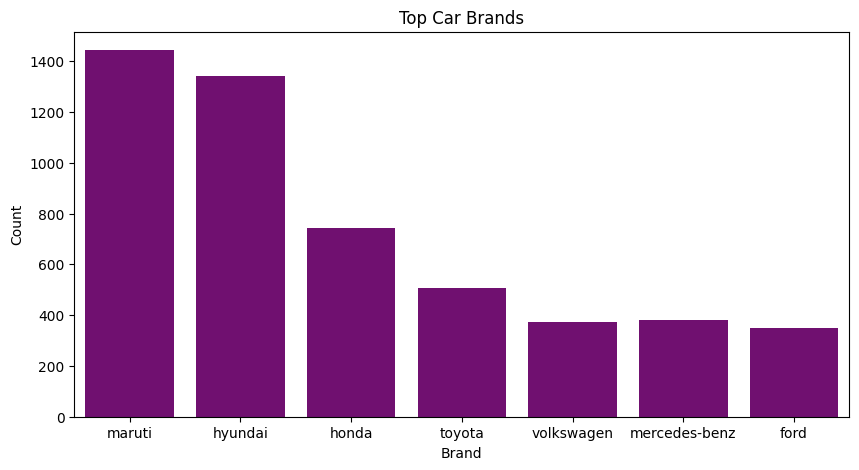

In [19]:
# Countplot for top brands
plt.figure(figsize=(10, 5))
top_brands = df["brand"].value_counts().head(7).index
sns.countplot(data=df[df["brand"].isin(top_brands)], x="brand", color="purple")
plt.title("Top Car Brands")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.show()

In [20]:
# Value counts of fuel types
df["Fuel_Type"].value_counts()

,count
Fuel_Type,
diesel,3852
petrol,3325
cng,62
lpg,12
electric,2


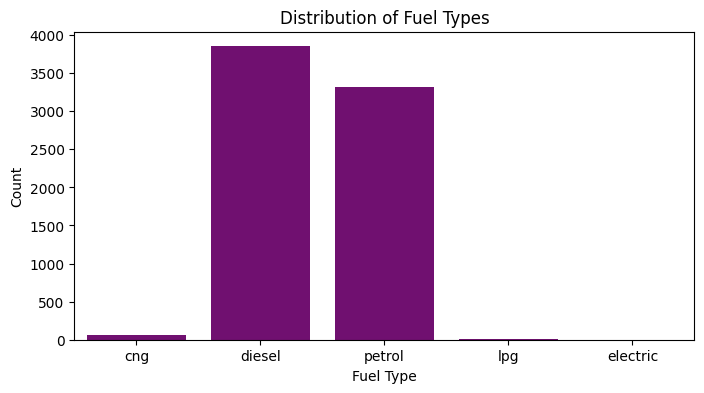

In [21]:
# Countplot for Fuel Type
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Fuel_Type", color="purple")
plt.title("Distribution of Fuel Types")
plt.xlabel("Fuel Type")
plt.ylabel("Count")
plt.show()

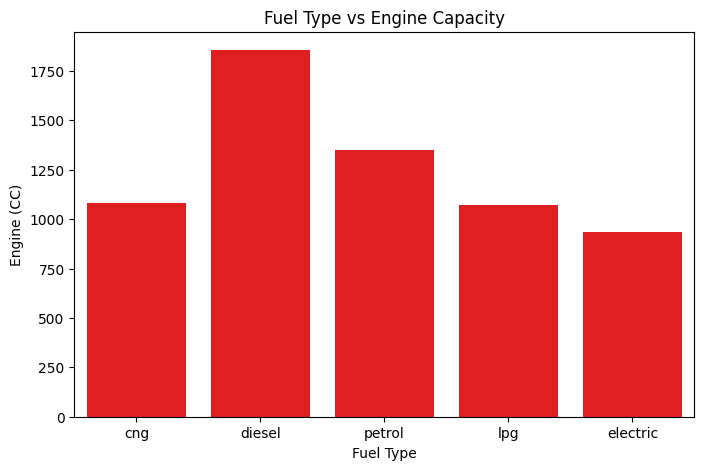

In [22]:
# Bivariate Analysis
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Fuel_Type", y="Engine", color="red", errorbar=None)
plt.title("Fuel Type vs Engine Capacity")
plt.xlabel("Fuel Type")
plt.ylabel("Engine (CC)")
plt.show()

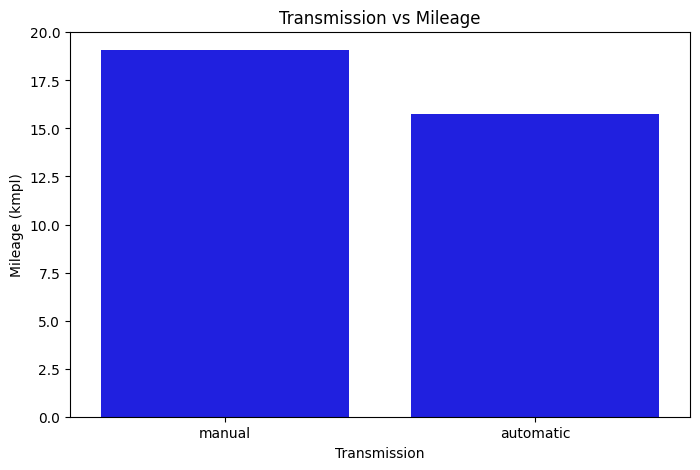

In [23]:
# Transmission vs Mileage
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Transmission", y="Mileage", color="blue", errorbar=None)
plt.title("Transmission vs Mileage")
plt.xlabel("Transmission")
plt.ylabel("Mileage (kmpl)")
plt.show()

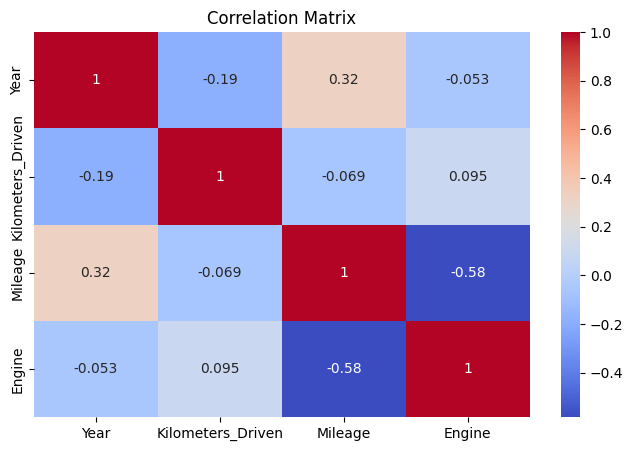

In [24]:
# Multivariate analysis
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(8, 5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

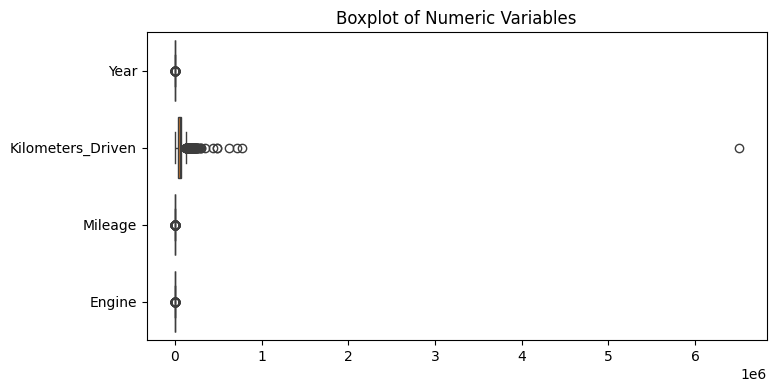

In [25]:
# outlier detection and removal
plt.figure(figsize=(8, 4))
sns.boxplot(data=numeric_df, orient="h")
plt.title("Boxplot of Numeric Variables")
plt.show()

In [26]:
# Outlier removal using IQR method
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

df = df.reset_index(drop=True)

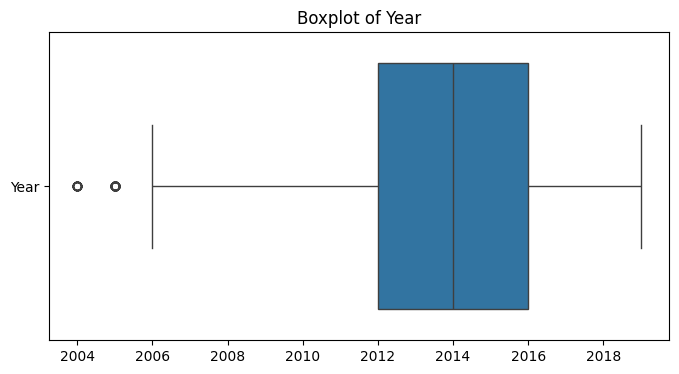

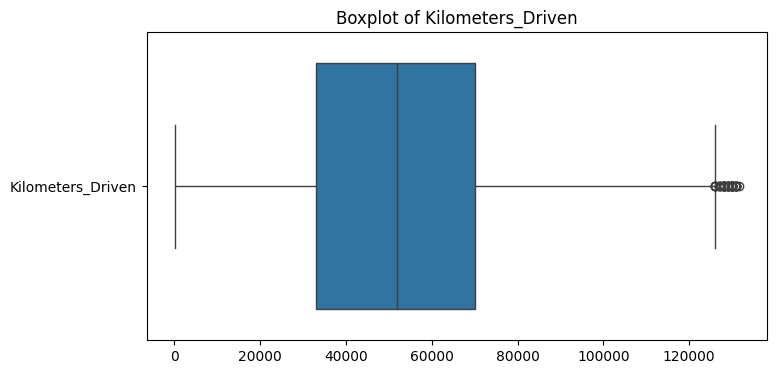

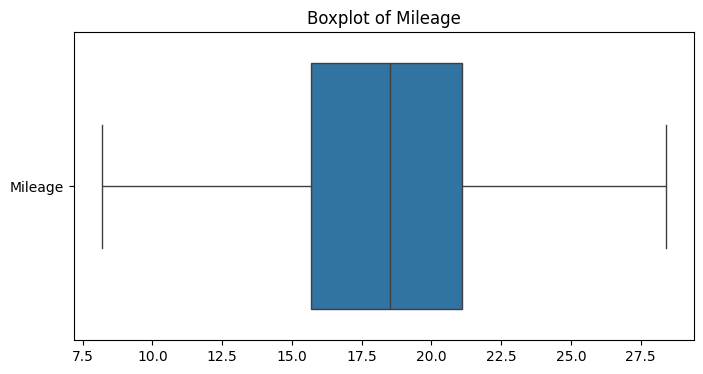

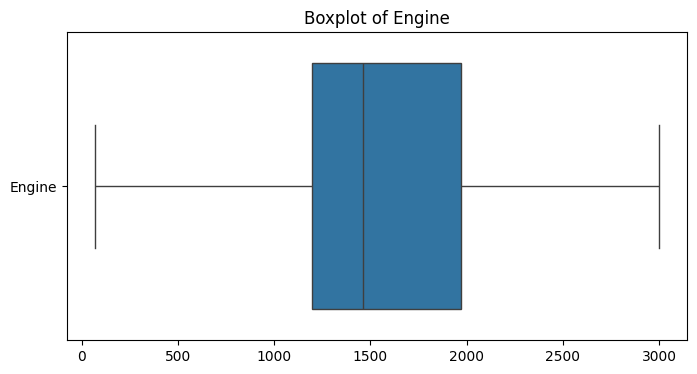

In [27]:
# Boxplot after outlier removal
numeric_df_clean = df.select_dtypes(include=np.number)
for col in numeric_df_clean.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=numeric_df_clean[[col]], orient="h")
    plt.title(f"Boxplot of {col}")
    plt.show()

In [31]:
# define categorical columns
categorical_columns = ['brand', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type']

# one -hot encoding
df_encoded = pd.get_dummies(df, columns = categorical_columns, drop_first = True, dtype = int)

df_encoded.head()

,Year,Kilometers_Driven,Mileage,Engine,brand_bmw,brand_chevrolet,brand_datsun,brand_fiat,brand_force,brand_ford,...,Location_mumbai,Location_pune,Fuel_Type_diesel,Fuel_Type_electric,Fuel_Type_lpg,Fuel_Type_petrol,Transmission_manual,Owner_Type_fourth & above,Owner_Type_second,Owner_Type_third
0,2010,72000,26.60,998.0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0
1,2015,41000,19.67,1582.0,0,0,0,0,0,0,...,0,1,1,0,0,0,1,0,0,0
2,2011,46000,18.20,1199.0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
3,2012,87000,20.77,1248.0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
4,2013,40670,15.20,1968.0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0


In [32]:
print(df_encoded.dtypes)
df_encoded.head()


Year                           int64
Kilometers_Driven              int64
Mileage                      float64
Engine                       float64
brand_bmw                      int64
brand_chevrolet                int64
brand_datsun                   int64
brand_fiat                     int64
brand_force                    int64
brand_ford                     int64
brand_honda                    int64
brand_hyundai                  int64
brand_isuzu                    int64
brand_jaguar                   int64
brand_jeep                     int64
brand_land                     int64
brand_mahindra                 int64
brand_maruti                   int64
brand_mercedes-benz            int64
brand_mini                     int64
brand_mitsubishi               int64
brand_nissan                   int64
brand_opelcorsa                int64
brand_porsche                  int64
brand_renault                  int64
brand_skoda                    int64
brand_tata                     int64
b

,Year,Kilometers_Driven,Mileage,Engine,brand_bmw,brand_chevrolet,brand_datsun,brand_fiat,brand_force,brand_ford,...,Location_mumbai,Location_pune,Fuel_Type_diesel,Fuel_Type_electric,Fuel_Type_lpg,Fuel_Type_petrol,Transmission_manual,Owner_Type_fourth & above,Owner_Type_second,Owner_Type_third
0,2010,72000,26.60,998.0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0
1,2015,41000,19.67,1582.0,0,0,0,0,0,0,...,0,1,1,0,0,0,1,0,0,0
2,2011,46000,18.20,1199.0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
3,2012,87000,20.77,1248.0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
4,2013,40670,15.20,1968.0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
